# Ring resonator benchmark

Benchmarks Luminescent against Tidy3D and Lumerical FDTD using the ring resonator from Liu & Poon, [arXiv:2506.16665](https://arxiv.org/html/2506.16665v2), Sec. 3.6. The device is GDSFactory's generic `ring_single`: a 500 nm × 220 nm Si waveguide with 10 µm radius bends, a 4 µm coupler with a 0.2 µm gap, and 0.6 µm vertical straights. SiO2 cladding is above and below. Si uses a lossless Lorentzian fit to the paper's Palik model (n = 3.4729 at 1550 nm); SiO2 is constant n = 1.4425. The domain is the device plus 1 µm margins: 32 × 23.8 × 2.22 µm³ (the paper uses 32 × 24.05 × 4 µm³). TE0 enters o1 at 1550 nm with a λ/12 source bandwidth (the paper uses 20 nm). Transmission is sampled every 0.05 nm and interpolated to 0.02 nm. We report the lowest resonance λ0, the FWHM at half the dip depth, and Q = λ0 / FWHM. The energy shutoff is 1e-4 (1e-3 for nres ≤ 10; the paper uses 1e-5), with runs capped at 3000 periods. If a resonance splits into a doublet, the deeper dip is used.

Paper values (Tidy3D 2.7.7 on cloud GPUs, Lumerical 2025 R1 on a 24-core CPU; λ0, FWHM and Q digitized from Fig. 26):

| nres | λ0 Tidy3D / Lumerical [nm] | FWHM Tidy3D / Lumerical [nm] | Q Tidy3D / Lumerical | Tidy3D time | Lumerical time | Lumerical memory |
|---|---|---|---|---|---|---|
| 6 | 1547.28 / 1546.65 | 0.88 / 0.84 | 1757 / 1839 | 135 s | 1074 s | 3.14 GB |
| 10 | 1546.37 / 1545.61 | 0.88 / 0.88 | 1756 / 1755 | 236 s | 4527 s | 8.36 GB |
| 15 | 1545.77 / 1547.73 | 0.90 / 0.86 | 1716 / 1798 | 971 s | 16524 s | 18.50 GB |
| 20 | 1545.07 / 1545.57 | 0.88 / 0.90 | 1754 / 1716 | 2414 s | 44034 s | 32.62 GB |

## Setup

In [1]:
import os, time, json, threading, subprocess
import numpy as np
import psutil
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

import gdsfactory as gf
from gdsfactory.technology import LogicalLayer, LayerLevel, LayerStack
import luminescent as lumi

gf.gpdk.PDK.activate()

nres_list = [6, 10]
h_wg = 0.22
wavelength = 1.55
# bandwidth = wavelength / 4
bandwidth = wavelength / 12
wavelengths = np.linspace(1.54, 1.56, 401).tolist()  # 0.05 nm step

# domain margins [um]
margin = 1
zmargin = 1
zmin, zmax = -zmargin, h_wg + zmargin

lumi backend: ~/Luminescent/bin/lumi


In [2]:
def setup(path, nres):
    # Si: lossless single-Lorentzian fit to the paper's Palik model (frequency in units of c / wavelength); SiO2: constant
    materials = {
        "Si": lumi.material(n=3.4729, epsilon=8.36218, dispersion=[lumi.lorentzian(3.0, 0, 3.2882)]),
        "SiO2": lumi.material(1.4425),
    }
    WG = 1, 0
    layer_stack = LayerStack(
        layers={
            "core": LayerLevel(
                layer=LogicalLayer(layer=WG),
                thickness=h_wg,
                zmin=0,
                material="Si",
                mesh_order=0,
            ),
        }
    )

    # GDSFactory generic ring_single: gap 0.2, length_x 4, length_y 0.6, radius 10
    ring = gf.components.ring_single()
    xmin, ymin = ring.bbox_np()[0]
    xmax, ymax = ring.bbox_np()[1]
    bbox = [[xmin - margin, ymin - margin, zmin], [xmax + margin, ymax + margin, zmax]]

    # 10 um port extensions, cropped to the domain
    ext = gf.components.extend_ports(ring, length=10)
    dbu = ext.kcl.dbu
    wg = gf.kdb.Region(ext.begin_shapes_rec(ext.kcl.layer(*WG)))
    window = gf.kdb.Region(gf.kdb.Box(*(round(v / dbu) for v in (bbox[0][0], bbox[0][1], bbox[1][0], bbox[1][1]))))
    c = gf.Component()
    c.add_polygon(wg & window, layer=WG)
    for p in ring.ports:
        c.add_port(p.name, center=p.center, width=p.width, orientation=p.orientation, layer=WG)
    c.plot()

    frames = [
        lumi.plane_frame(
            "wg",
            start=[-1.2, zmin],
            stop=[1.2, zmax],
            wls_mode_solver=[wavelengths[0], wavelength, wavelengths[-1]],
        )
    ]
    sources = [
        lumi.gf_source("o1", c, layer_stack, margin, frame="wg", wl=wavelength, bandwidth=bandwidth)
    ]
    monitors = [lumi.gf_monitor(p, c, layer_stack, frame="wg") for p in ["o1", "o2"]]

    lumi.mesh(path, c, layer_stack, materials, zmin, zmax)
    lumi.setup(
        path=path,
        wl=wavelength,
        wls=wavelengths,
        materials=materials,
        background="SiO2",
        boundaries=["PML", "PML", "PML"],
        PML_decay=[0.001, 0.001, 0.1],
        bbox=bbox,
        frames=frames,
        sources=sources,
        monitors=monitors,
        nres=nres,
        tmax=3000,  # periods
        shutoff=1e-4,
        views=[lumi.view("Hz", z=h_wg / 2)],
        shot_every=10,
    )
    return c

## Simulate

In [3]:
def gpu_used():
    out = subprocess.run(["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"], capture_output=True, text=True).stdout
    return sum(float(v) for v in out.split()) / 1024  # GB


def solve_with_stats(path):
    """solve, tracking wall time, peak GPU memory (above baseline) and peak solver host RSS"""
    peak = {"gpu": 0.0, "host": 0.0}
    base = gpu_used()
    me = psutil.Process()
    done = threading.Event()

    def poll():
        while not done.is_set():
            peak["gpu"] = max(peak["gpu"], gpu_used() - base)
            rss = 0
            for p in me.children(recursive=True):
                try:
                    rss += p.memory_info().rss
                except psutil.Error:
                    pass
            peak["host"] = max(peak["host"], rss / 1024**3)
            time.sleep(0.5)

    t = threading.Thread(target=poll)
    t.start()
    t0 = time.time()
    try:
        lumi.solve(path)
    finally:
        done.set()
        t.join()
    stats = {"runtime": time.time() - t0, "gpu_GB": peak["gpu"], "host_GB": peak["host"]}
    json.dump(stats, open(os.path.join(path, "stats.json"), "w"))
    return stats

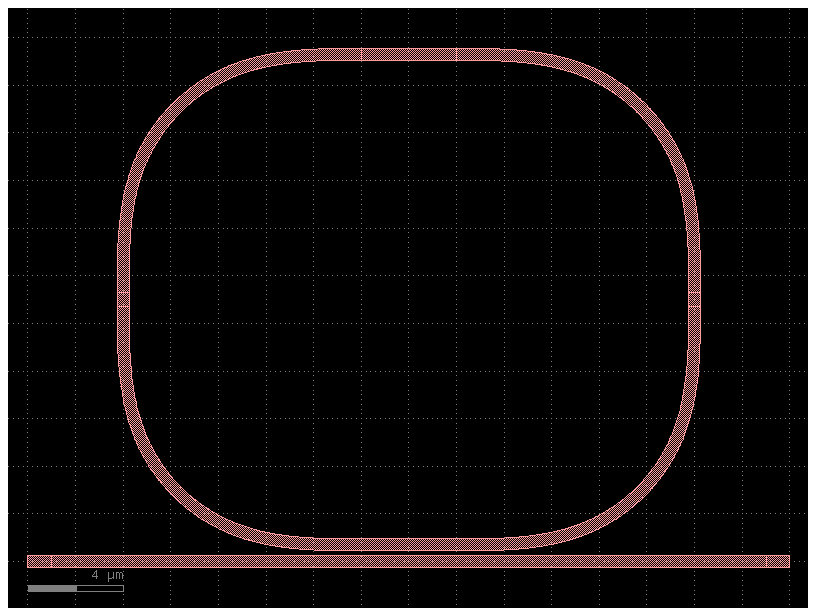

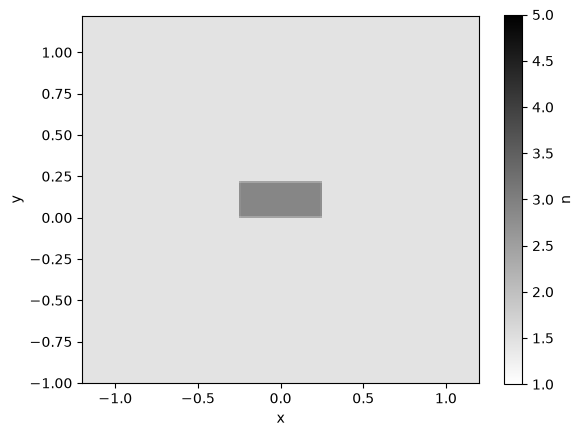

using simulation folder runs/ring_nres6


backend using simulation folder runs/ring_nres6


setting up simulation...


processing geometry bodies...


generating voxels...


voxelation: 13.860563 seconds (750.41 M allocations: 29.796 GiB, 38.50% gc time, 147.48% compilation time)


... (305 outputs left out)

period 2,990, decay: 0.002, 0.038 seconds/period, 8490.48 Mcells/s


period 3,000, decay: 0.002, 0.038 seconds/period, 8464.99 Mcells/s
8474.13 Mcells/s


simulation completed.


{'runtime': 322.9844379425049, 'gpu_GB': 2.3291015625, 'host_GB': 3.6702232360839844}


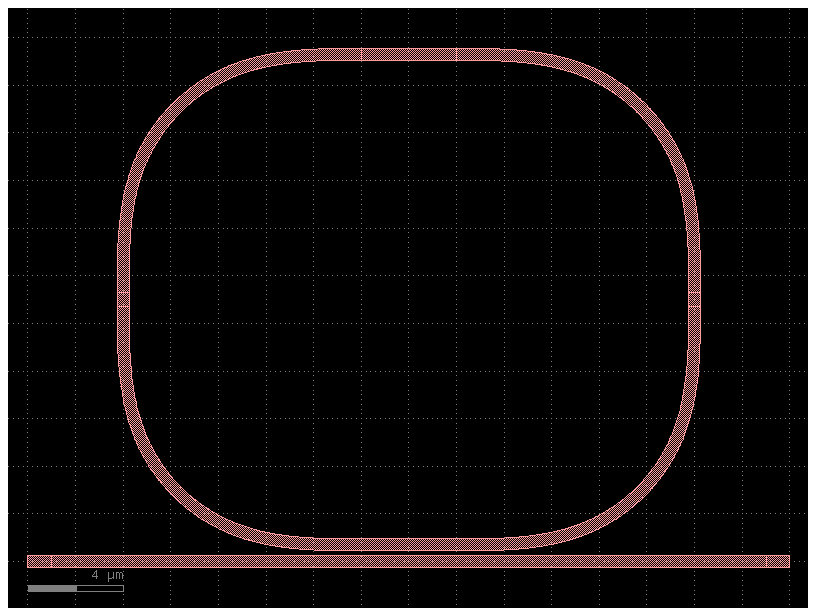

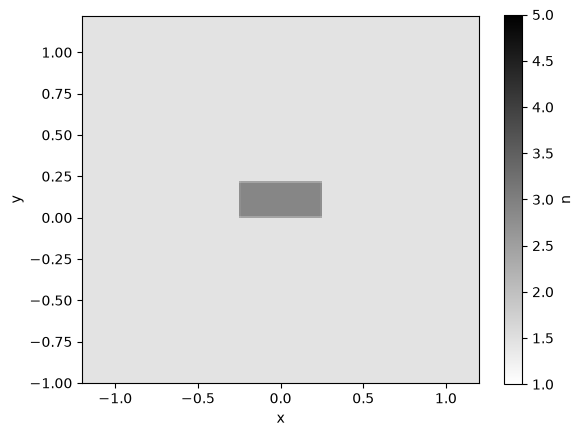

using simulation folder runs/ring_nres10


backend using simulation folder runs/ring_nres10


setting up simulation...


processing geometry bodies...


generating voxels...


voxelation: 43.856250 seconds (2.51 G allocations: 93.027 GiB, 46.48% gc time, 41.36% compilation time)


... (306 outputs left out)

period 2,990, decay: 0.005, 0.242 seconds/period, 8737.94 Mcells/s


period 3,000, decay: 0.005, 0.242 seconds/period, 8734.96 Mcells/s
8809.94 Mcells/s


simulation completed.


{'runtime': 1017.4534919261932, 'gpu_GB': 7.6416015625, 'host_GB': 6.921794891357422}


In [4]:
for nres in nres_list:
    path = os.path.join("runs", f"ring_nres{nres}")
    setup(path, nres)
    print(solve_with_stats(path))

## Results

loading solution from runs/ring_nres6
may take a minute if simulation folder is remotely mounted
loading solution from runs/ring_nres10
may take a minute if simulation folder is remotely mounted


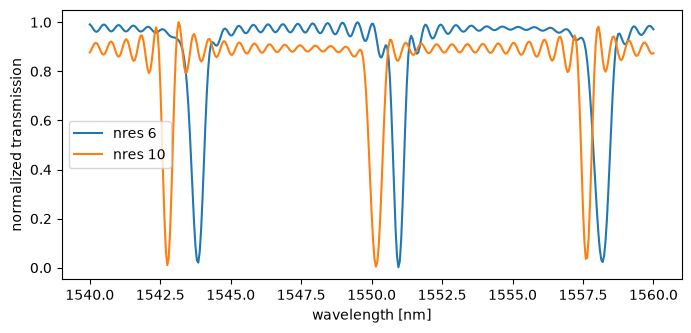

nres  λ0 [nm]   FWHM [nm]  Q      runtime  GPU mem  host mem
   6   1543.84     0.507    3046    323 s   2.33 GB   3.67 GB
  10   1542.76     0.379    4067   1017 s   7.64 GB   6.92 GB


In [5]:
def resonance(wls_nm, T):
    """lowest-wavelength resonance of normalized T: (λ0, FWHM at half dip depth); deeper dip of a doublet"""
    x = np.arange(wls_nm[0], wls_nm[-1], 0.02)
    y = CubicSpline(wls_nm, T)(x)
    dips = [k for k in range(1, len(y) - 1) if y[k] < y[k - 1] and y[k] <= y[k + 1] and y[k] < 0.5]

    def fwhm(k):
        win = abs(x - x[k]) < 3  # local max within ±3 nm (FSR ≈ 7.5 nm)
        half = (y[win].max() + y[k]) / 2
        l = k
        while y[l] < half:
            l -= 1
        r = k
        while y[r] < half:
            r += 1
        # linear interpolation of the half-level crossings
        xl = x[l] + (half - y[l]) / (y[l + 1] - y[l]) * (x[l + 1] - x[l])
        xr = x[r - 1] + (half - y[r - 1]) / (y[r] - y[r - 1]) * (x[r] - x[r - 1])
        return xr - xl

    pair = [d for d in dips if x[d] - x[dips[0]] < 2]  # doublet halves lie within 2 nm
    k = min(pair, key=lambda d: y[d])
    return x[k], fwhm(k)


wls_nm = 1000 * np.array(wavelengths)
rows = []
plt.figure(figsize=(8, 3.5))
for nres in [6, 10, 15, 20]:
    path = os.path.join("runs", f"ring_nres{nres}")
    if not os.path.exists(os.path.join(path, "solution.json")):
        continue
    m = lumi.load(path)["monitors"]
    T = np.abs(m["o2"]["modes"][0]["+"] / m["o1"]["modes"][0]["-"]) ** 2
    T = T / T.max()
    lam0, fwhm = resonance(wls_nm, T)
    f = os.path.join(path, "stats.json")
    st = json.load(open(f)) if os.path.exists(f) else {}
    rows.append((nres, lam0, fwhm, lam0 / fwhm, st.get("runtime"), st.get("gpu_GB"), st.get("host_GB")))
    plt.plot(wls_nm, T, label=f"nres {nres}")
plt.xlabel("wavelength [nm]")
plt.ylabel("normalized transmission")
plt.legend()
plt.show()

fmt = lambda v, f: "–" if v is None else format(v, f)
print("nres  λ0 [nm]   FWHM [nm]  Q      runtime  GPU mem  host mem")
for nres, lam0, fwhm, Q, rt, g, h in rows:
    print(f"{nres:4d}  {lam0:8.2f}  {fwhm:8.3f}  {Q:6.0f}  {fmt(rt, '5.0f'):>5} s  {fmt(g, '5.2f'):>5} GB  {fmt(h, '5.2f'):>5} GB")

## Grid

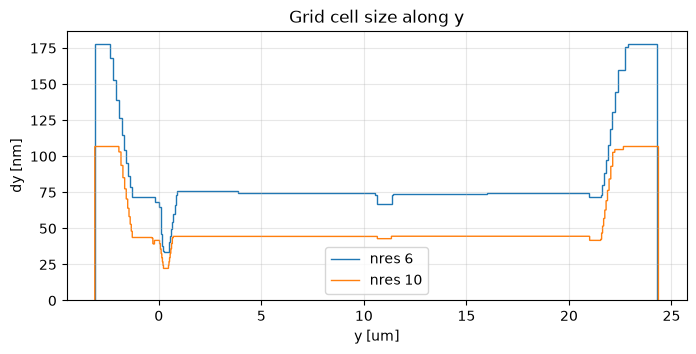

In [6]:
# grid cell sizes along y; rulers are stored in units of the wavelength
plt.figure(figsize=(8, 3.5))
for nres in [6, 10, 15, 20]:
    f = os.path.join("runs", f"ring_nres{nres}", "grid.json.dat", "_REF_rulers_._1.npy")
    if not os.path.exists(f):
        continue
    y = wavelength * np.load(f)
    plt.stairs(1000 * np.diff(y), y, label=f"nres {nres}")
plt.xlabel("y [um]")
plt.ylabel("dy [nm]")
plt.title("Grid cell size along y")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## Fig. 26a–c comparison

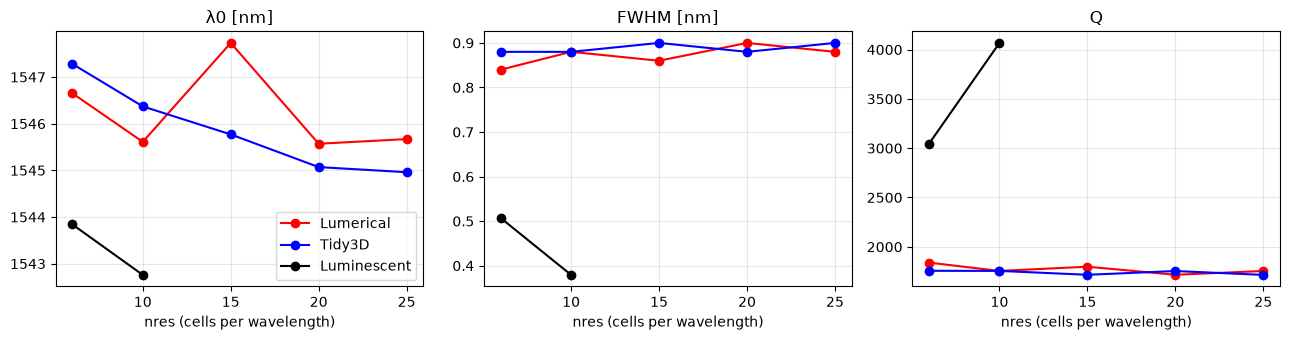

In [7]:
# paper Fig. 26a-c, digitized
nres_paper = [6, 10, 15, 20, 25]
paper = {
    "λ0 [nm]": ([1547.28, 1546.37, 1545.77, 1545.07, 1544.96], [1546.65, 1545.61, 1547.73, 1545.57, 1545.67]),
    "FWHM [nm]": ([0.88, 0.88, 0.90, 0.88, 0.90], [0.84, 0.88, 0.86, 0.90, 0.88]),
    "Q": ([1756.5, 1755.5, 1716, 1754, 1714.9], [1839.4, 1755, 1798, 1716, 1754.7]),
}

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
for a, (name, (tidy3d, lumerical)), col in zip(ax, paper.items(), [1, 2, 3]):
    a.plot(nres_paper, lumerical, "o-", color="red", label="Lumerical")
    a.plot(nres_paper, tidy3d, "o-", color="blue", label="Tidy3D")
    a.plot([r[0] for r in rows], [r[col] for r in rows], "o-", color="black", label="Luminescent")
    a.set(xlabel="nres (cells per wavelength)", title=name)
    a.grid(alpha=0.3)
ax[0].legend()
plt.tight_layout()
plt.show()

## Movie

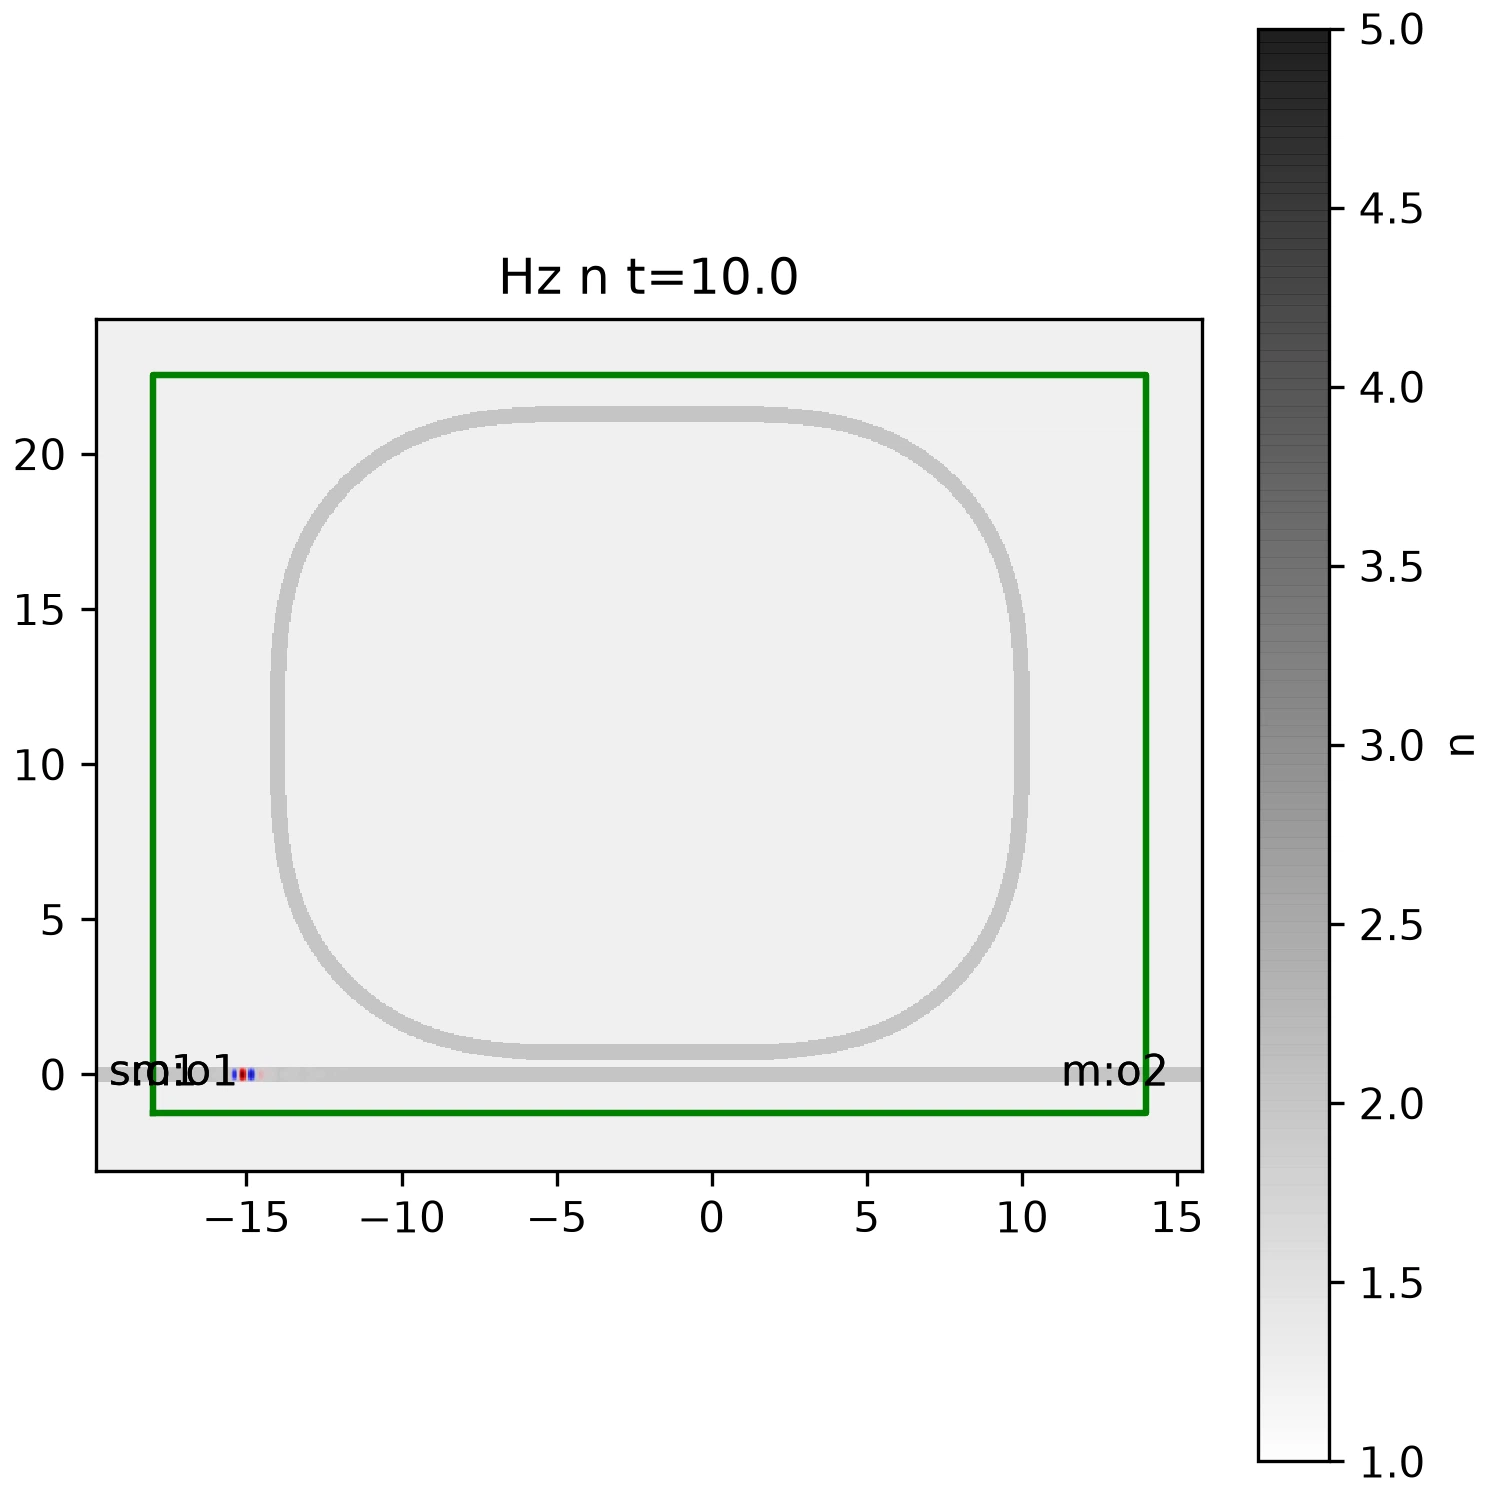

In [8]:
lumi.movie(os.path.join("runs", f"ring_nres{nres_list[-1]}"))